In [1]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2
from src.data_io import load_trip

left_data=load_trip("../data/raw/PSV1",'left')
right_data=load_trip("../data/raw/PSV1",'right')
print(left_data.shape,right_data.shape)

(144036, 48) (144036, 48)


In [2]:
# Determination of frozen data

from src.preprocessing import flag_frozen

for side, df in [('left', left_data),('right', right_data)]:
    df['frozen']=flag_frozen(df['acc_z_below_suspension'])
    print(side, df['frozen'].sum(), 'rows', round(100*df['frozen'].mean(),2), '%')

left 159 rows 0.11 %
right 928 rows 0.64 %


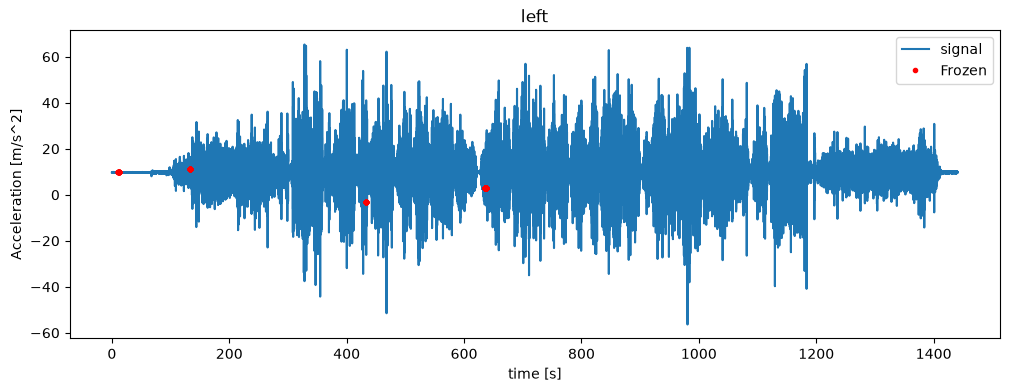

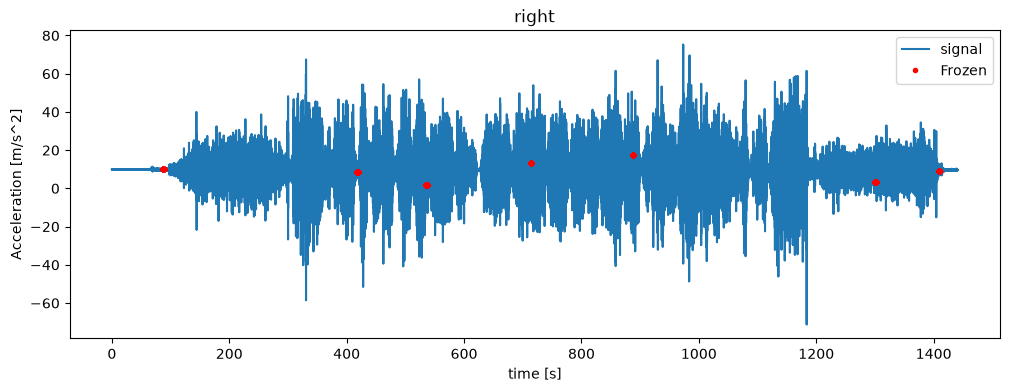

In [3]:
import matplotlib.pyplot as plt

for side, df in [('left', left_data),('right', right_data)]:
    frozen_rows=df[df['frozen']]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(df['t'], df['acc_z_below_suspension'], label='signal')
    ax.plot(frozen_rows['t'], frozen_rows['acc_z_below_suspension'],'r.', label='Frozen')
    ax.set_title(side)
    ax.set_xlabel('time [s]')
    ax.set_ylabel('Acceleration [m/s^2]')
    ax.legend()
    plt.show()

In [4]:
positions=['dashboard', 'above_suspension', 'below_suspension']

for side, df in [('left', left_data),('right', right_data)]:
    for pos in positions:
        df[f'frozen_{pos}']=flag_frozen(df[f'acc_z_{pos}'])
        print(side, pos, df[f'frozen_{pos}'].sum(), 'rows')

    frozen_cols = [f'frozen_{pos}' for pos in positions]
    df['frozen']=df[frozen_cols].any(axis=1)
    print(side, 'any position:', df['frozen'].sum(), 'rows', round(100*df['frozen'].mean(),2))

left dashboard 167 rows
left above_suspension 179 rows
left below_suspension 159 rows
left any position: 202 rows 0.14
right dashboard 934 rows
right above_suspension 949 rows
right below_suspension 928 rows
right any position: 970 rows 0.67


In [5]:
# Filter saturated data (accelerometer +-8g in z)

for side, df in [('left', left_data), ('right', right_data)]:
    for pos in positions:
        df[f'saturated_{pos}']= (df[f'acc_z_{pos}'].abs() >= 0.96*(9.81*8))
        print(side, pos, df[f'saturated_{pos}'].sum(), 'rows')

    saturated_cols= [f'saturated_{pos}' for pos in positions]
    df['saturated']=df[saturated_cols].any(axis=1)
    print(side, 'any position:',df['saturated'].sum(), 'rows')

    df['invalid']=df['frozen'] | df['saturated']
    print(side, 'invalid:', df['invalid'].sum(), 'rows', round(100*df['invalid'].mean(),2), '%')

cols = [f'acc_z_{pos}' for pos in positions]
print(left_data[cols].abs().max())
print(right_data[cols].abs().max())

left dashboard 0 rows
left above_suspension 0 rows
left below_suspension 0 rows
left any position: 0 rows
left invalid: 202 rows 0.14 %
right dashboard 0 rows
right above_suspension 0 rows
right below_suspension 0 rows
right any position: 0 rows
right invalid: 970 rows 0.67 %
acc_z_dashboard           24.665544
acc_z_above_suspension    24.333819
acc_z_below_suspension    65.335711
dtype: float64
acc_z_dashboard           24.372434
acc_z_above_suspension    27.827631
acc_z_below_suspension    75.285146
dtype: float64


In [6]:
from src.preprocessing import bandpass

f_low, f_high, fs = 0.5, 40, 100

for side, df in [('left', left_data), ('right', right_data)]:
    for pos in positions:
        df[f'acc_z_{pos}_filt']=bandpass(df[f'acc_z_{pos}'],f_low,f_high,fs)

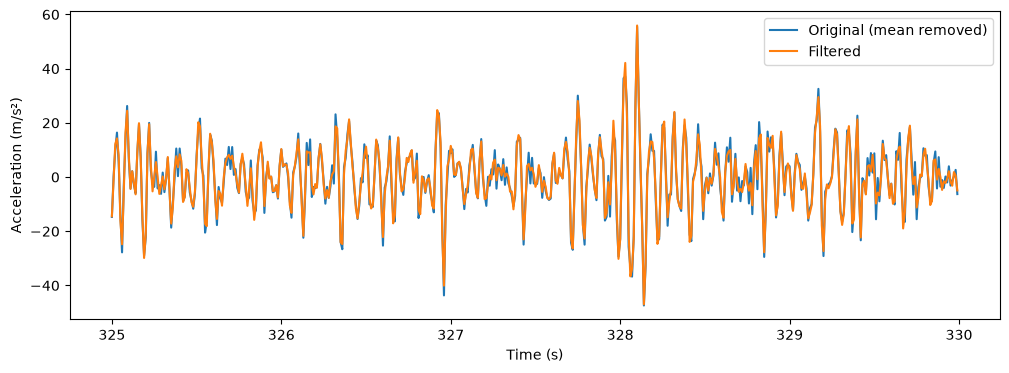

In [7]:
seg = left_data[(left_data['t'] >= 325) & (left_data['t'] < 330)]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(seg['t'], seg['acc_z_below_suspension'] - seg['acc_z_below_suspension'].mean(), label='Original (mean removed)')
ax.plot(seg['t'], seg['acc_z_below_suspension_filt'], label='Filtered')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Acceleration (m/s²)')
ax.legend()
plt.show()

In [8]:
from src.preprocessing import make_windows

trips = {}
for side, df in [('left', left_data), ('right', right_data)]:
    df_w, windows = make_windows(df)
    trips[side] = (df_w, windows)
    print(side, 'valid windows:', windows['valid'].sum(), 'of', len(windows))
    print(windows[windows['valid']].groupby('surface').size())

left valid windows: 214 of 294
surface
asphalt_road        75
cobblestone_road    98
dirt_road           41
dtype: int64
right valid windows: 211 of 294
surface
asphalt_road        75
cobblestone_road    94
dirt_road           42
dtype: int64


In [9]:
from pathlib import Path

out = Path('../data/processed')
signal_cols = ['t', 'window', 'surface', 'speed'] + [f'acc_z_{pos}_filt' for pos in positions]

for side, (df_w, windows) in trips.items():
    windows = windows.assign(trip='PVS1', side=side)
    windows.to_csv(out / f'windows_PVS1_{side}.csv')
    df_w[signal_cols].to_parquet(out / f'signals_PVS1_{side}.parquet')

## Part 2 – Conclusions
1. **Frozen data:** 0.11 % (left) and 0.64 % (right) of samples were frozen in at least one sensor. Frozen segments mostly occur simultaneously in all three positions. A sample is marked invalid if any position is frozen.
2. **Saturation:** no saturation was found. Maximum vertical accelerations were 65.3 m/s^2 (left) and 75.3 m/s^2 (right), below the 96% threshold of the +-78.5 m/s^2 sensor range, although the right-side peak reaches 96% of the range.
3. **Filtering:** 4th-order Butterworth band-pass, 0.5–40 Hz. The high-pass removes gravity and slow variations (gradients, braking); the low-pass removes the poorly resolved band near the Nyquist frequency (50 Hz). Applied with `sosfiltfilt`: zero phase (no time shift between positions) and second-order sections for numerical stability at a cut-off that is low relative to the sampling frequency.
4. **Windowing:** 5s windows that never cross a surface change. Valid windows: single surface, mean speed > 10 km/h, speed std < 1 m/s, no invalid samples. Result: 214 of 294 windows valid on the left (75 asphalt, 98 cobblestone, 41 dirt) and 211 on the right; most discarded windows correspond to low speed.

# Notes
1. **filtfilt vs lfilter:** `lfilter` introduces a frequency-dependent phase shift, delaying the filtered signal. `filtfilt` filters forwards and backwards, cancelling the shift (zero phase), so peaks stay at the same time in all positions. This is essential to compare signals above and below the suspension and to estimate transmissibility.
2. **Window length trade-off:** shorter windows give more windows and lose less data at surface or speed changes, but poorer frequency resolution (delta_f = 1/T, 0.2Hz for 5s) and noisier per-window estimates. Longer windows improve frequency resolution and statistical stability, but give fewer windows and are more likely to include speed or surface changes, so more data is discarded.